<a href="https://colab.research.google.com/github/wadeea23/ECG-Based-Heartbeat-Classification-Using-Machine-Learning/blob/main/caps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
zip_path = '/content/drive/MyDrive/GA/Capstone_GA/heartbeat.zip'

In [4]:
import zipfile

zip_path = '/content/drive/MyDrive/GA/Capstone_GA/heartbeat.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/heartbeat')

In [5]:
import os
os.listdir('/content/heartbeat')

['mitbih_test.csv',
 'mitbih_train.csv',
 'ptbdb_abnormal.csv',
 'ptbdb_normal.csv']

In [6]:
! pip install imblearn

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
import seaborn as sns
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score , f1_score , confusion_matrix , classification_report
from sklearn.tree import plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPool2D, AveragePooling2D, Rescaling, Dropout,Conv1D, MaxPooling1D



In [8]:
train = pd.read_csv('/content/heartbeat/mitbih_train.csv',header=None)
test = pd.read_csv('/content/heartbeat/mitbih_test.csv',header=None)

In [9]:
train

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87549,0.807018,0.494737,0.536842,0.529825,0.491228,0.484211,0.456140,0.396491,0.284211,0.136842,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
87550,0.718333,0.605000,0.486667,0.361667,0.231667,0.120000,0.051667,0.001667,0.000000,0.013333,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
87551,0.906122,0.624490,0.595918,0.575510,0.530612,0.481633,0.444898,0.387755,0.322449,0.191837,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
87552,0.858228,0.645570,0.845570,0.248101,0.167089,0.131646,0.121519,0.121519,0.118987,0.103797,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0


In [10]:
test

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.758264,0.111570,0.000000,0.080579,0.078512,0.066116,0.049587,0.047521,0.035124,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.908425,0.783883,0.531136,0.362637,0.366300,0.344322,0.333333,0.307692,0.296703,0.300366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.730088,0.212389,0.000000,0.119469,0.101770,0.101770,0.110619,0.123894,0.115044,0.132743,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.910417,0.681250,0.472917,0.229167,0.068750,0.000000,0.004167,0.014583,0.054167,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.570470,0.399329,0.238255,0.147651,0.000000,0.003356,0.040268,0.080537,0.070470,0.090604,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21887,0.928736,0.871264,0.804598,0.742529,0.650575,0.535632,0.394253,0.250575,0.140230,0.102299,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
21888,0.802691,0.692078,0.587444,0.446936,0.318386,0.189836,0.118087,0.077728,0.112108,0.152466,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
21889,1.000000,0.967359,0.620178,0.347181,0.139466,0.089021,0.103858,0.100890,0.106825,0.100890,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
21890,0.984127,0.567460,0.607143,0.583333,0.607143,0.575397,0.575397,0.488095,0.392857,0.238095,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0


In [11]:
print(train.shape)
print(test.shape)

(87554, 188)
(21892, 188)


In [12]:
train.describe()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
count,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,...,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000
mean,0.890360,0.758160,0.423972,0.219104,0.201127,0.210399,0.205808,0.201773,0.198691,0.196757,...,0.005025,0.004628,0.004291,0.003945,0.003681,0.003471,0.003221,0.002945,0.002807,0.473376
std,0.240909,0.221813,0.227305,0.206878,0.177058,0.171909,0.178481,0.177240,0.171778,0.168357,...,0.044154,0.042089,0.040525,0.038651,0.037193,0.036255,0.034789,0.032865,0.031924,1.143184
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.921922,0.682486,0.250969,0.048458,0.082329,0.088416,0.073333,0.066116,0.065000,0.068639,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.991342,0.826013,0.429472,0.166000,0.147878,0.158798,0.145324,0.144424,0.150000,0.148734,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.910506,0.578767,0.341727,0.258993,0.287628,0.298237,0.295391,0.290832,0.283636,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000


In [13]:
train_percentage=train.iloc[:, -1].value_counts(normalize=True) * 100 # for known each class have  an percentage
train_percentage.sort_index()

,proportion
187,
0.0,82.772917
1.0,2.539005
2.0,6.610777
3.0,0.732120
4.0,7.345181


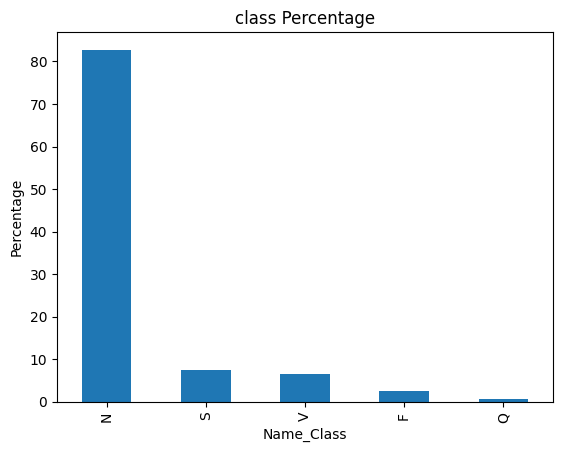

In [14]:
train_percentage.plot(kind='bar')
class_names = ['N', 'S', 'V', 'F', 'Q']
plt.xticks(range(len(class_names)), class_names)
plt.xlabel('Name_Class')
plt.ylabel('Percentage')
plt.title('class Percentage')
plt.show()

##### split the data to train i have 2 files - train & test , so no need to split it

In [15]:
X_train = train.iloc[:, :-1]
y_train= train.iloc[:, -1]

X_test = test.iloc[:, :-1]
y_test = test.iloc[:, -1]




In [16]:
y_train.value_counts().sort_index()

,count
187,
0.0,72471
1.0,2223
2.0,5788
3.0,641
4.0,6431


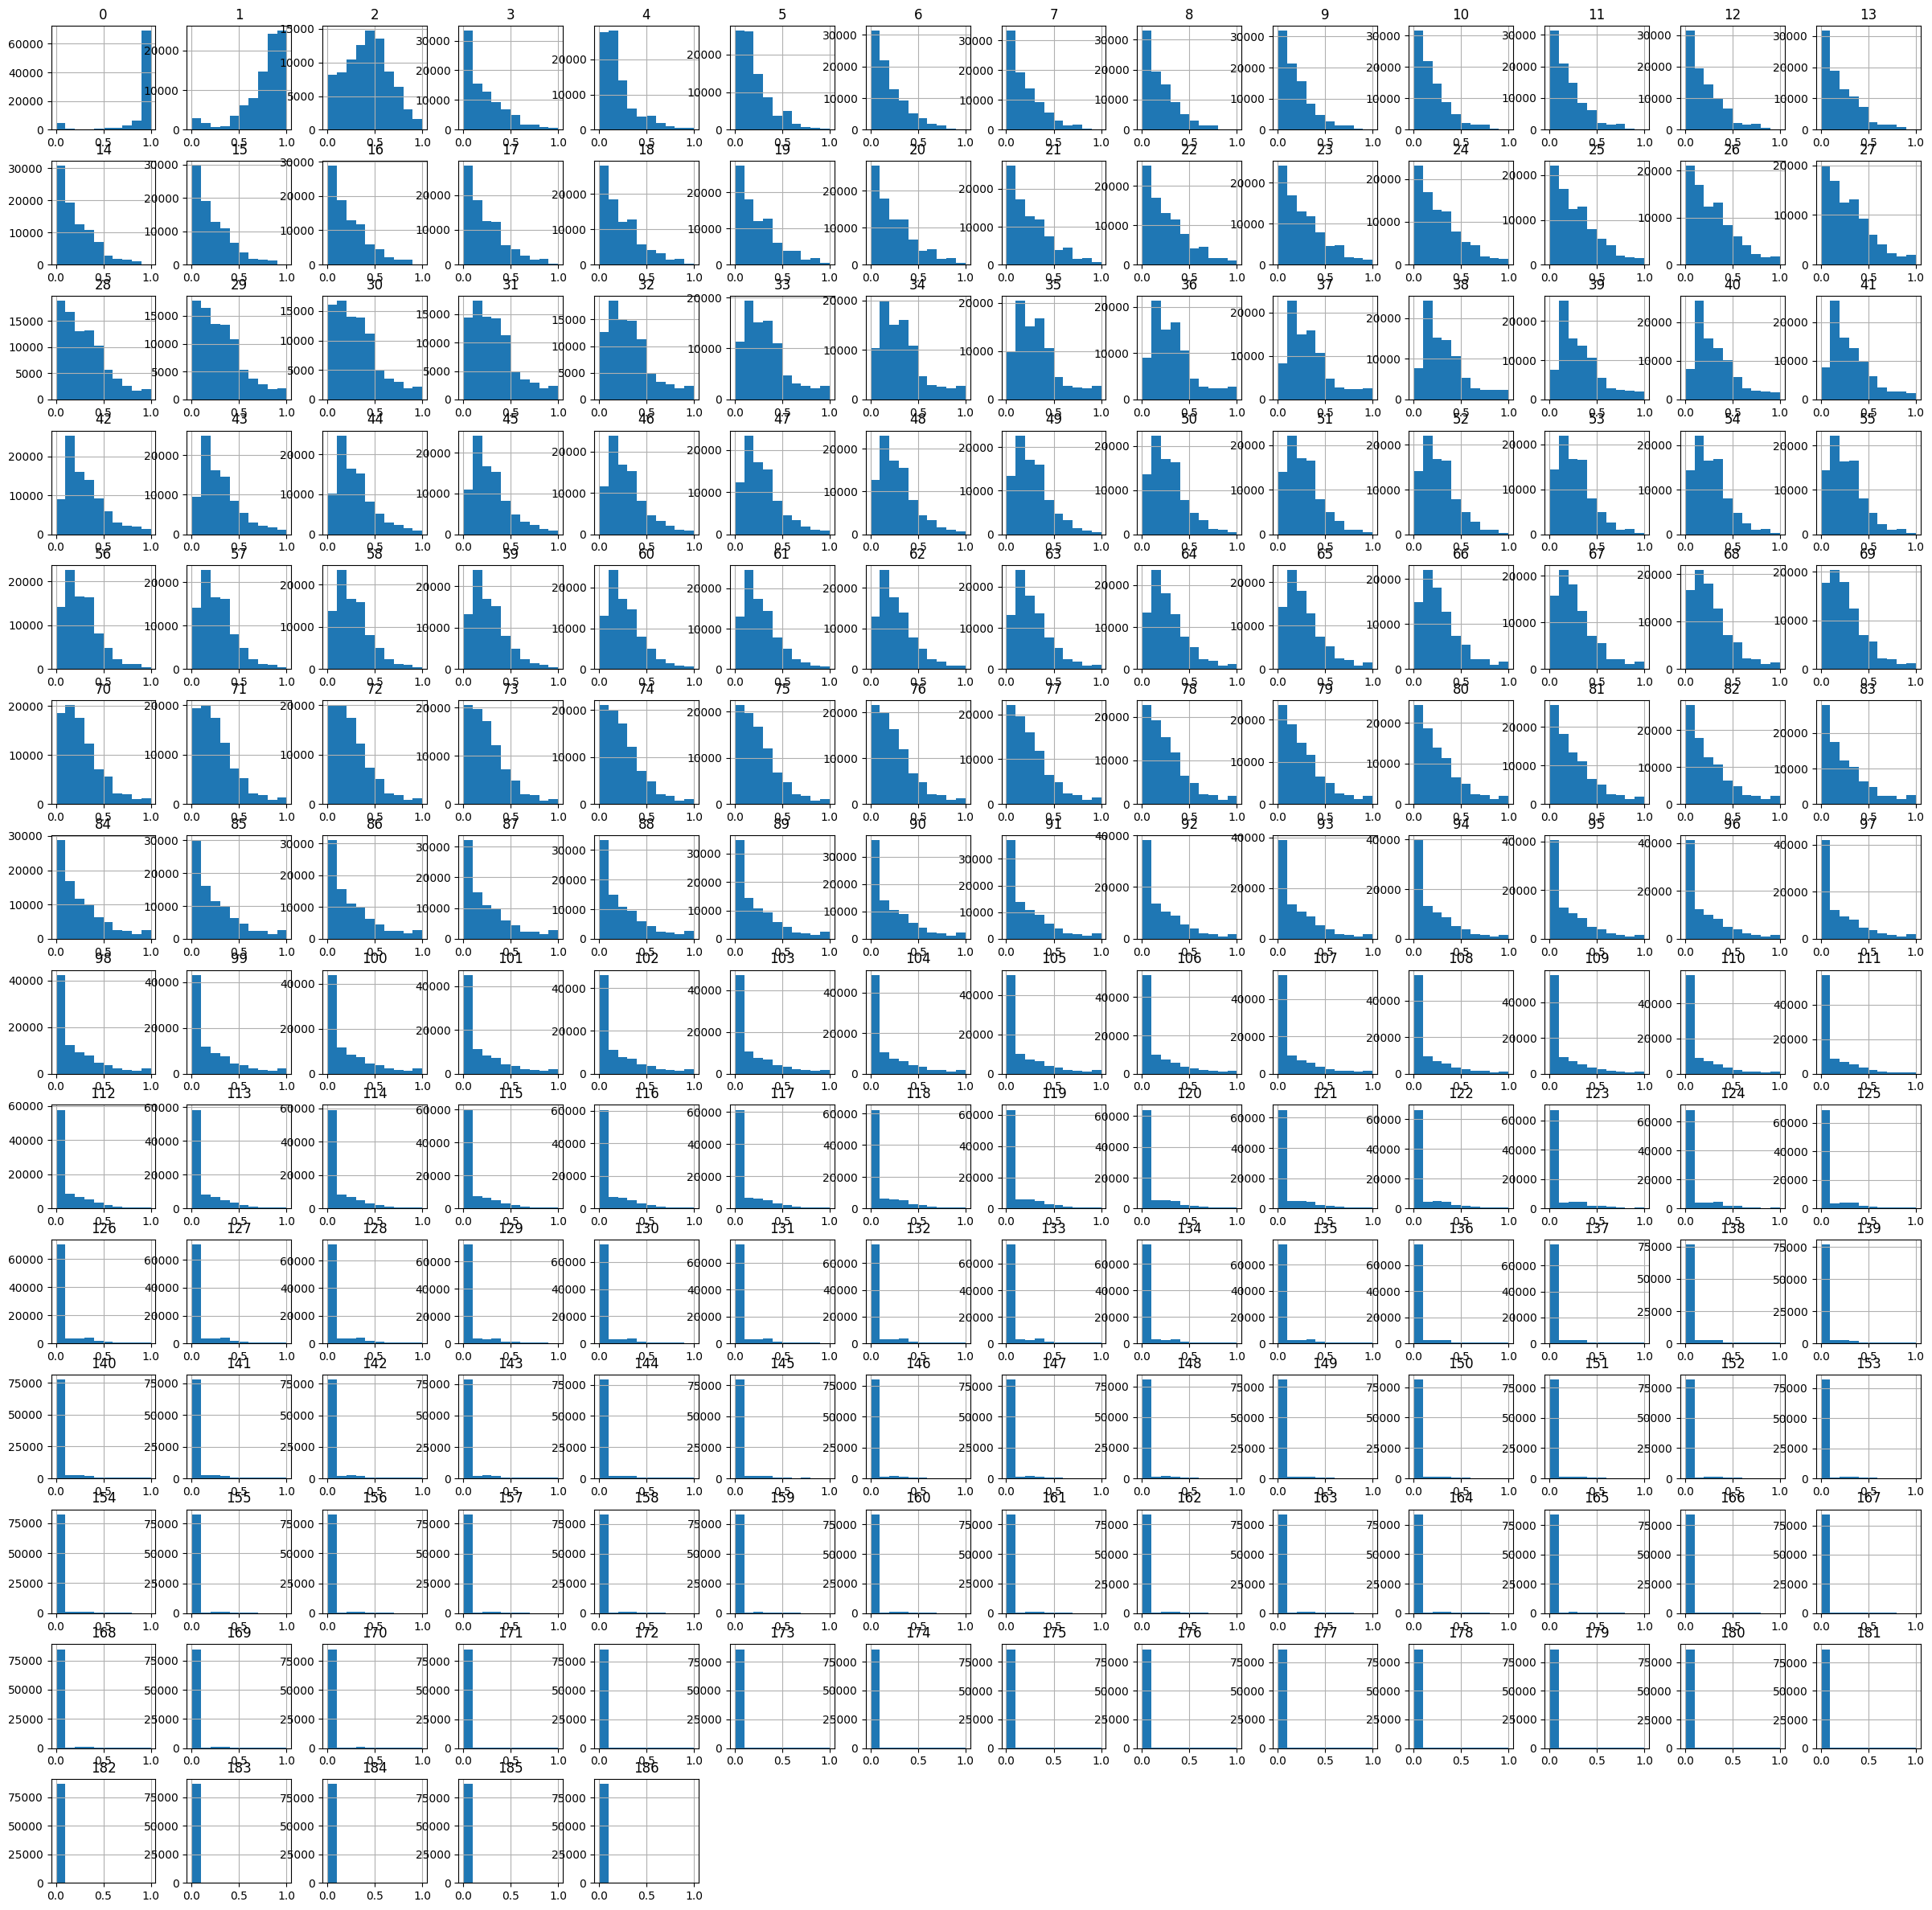

In [18]:
X_train.hist(figsize=(30, 30));

In [19]:
X_train.corr()

,0,1,2,3,4,5,6,7,8,9,...,177,178,179,180,181,182,183,184,185,186
0,1.000000,0.778516,0.141264,-0.134788,-0.243921,-0.352727,-0.430698,-0.480058,-0.521888,-0.559848,...,-0.056821,-0.051550,-0.044223,-0.039223,-0.035047,-0.035090,-0.035739,-0.035559,-0.033901,-0.032958
1,0.778516,1.000000,0.501528,-0.024286,-0.148470,-0.164901,-0.234436,-0.285260,-0.322706,-0.341306,...,-0.023208,-0.019324,-0.013356,-0.009154,-0.007511,-0.008674,-0.010175,-0.010693,-0.010116,-0.009987
2,0.141264,0.501528,1.000000,0.672398,0.402170,0.345925,0.281478,0.206464,0.138555,0.077503,...,-0.016131,-0.018531,-0.020627,-0.021478,-0.025592,-0.029119,-0.030466,-0.031462,-0.033109,-0.034741
3,-0.134788,-0.024286,0.672398,1.000000,0.819907,0.596827,0.475922,0.389027,0.292549,0.199308,...,-0.011305,-0.017025,-0.024396,-0.028907,-0.036101,-0.041249,-0.042956,-0.043560,-0.045399,-0.046860
4,-0.243921,-0.148470,0.402170,0.819907,1.000000,0.881908,0.750680,0.663960,0.563274,0.448298,...,0.027429,0.020470,0.010719,0.003458,-0.006081,-0.012639,-0.015318,-0.016064,-0.019551,-0.020914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,-0.035090,-0.008674,-0.029119,-0.041249,-0.012639,0.008180,0.007209,0.016548,0.023428,0.016330,...,0.721998,0.765540,0.819763,0.880913,0.950926,1.000000,0.958530,0.903837,0.852634,0.822765
183,-0.035739,-0.010175,-0.030466,-0.042956,-0.015318,0.005908,0.005361,0.015440,0.023275,0.016165,...,0.700719,0.738338,0.783177,0.832193,0.895911,0.958530,1.000000,0.953214,0.893247,0.855729
184,-0.035559,-0.010693,-0.031462,-0.043560,-0.016064,0.004372,0.003806,0.014076,0.022634,0.015333,...,0.680313,0.714502,0.753969,0.796068,0.848370,0.903837,0.953214,1.000000,0.948725,0.904684
185,-0.033901,-0.010116,-0.033109,-0.045399,-0.019551,0.000171,0.000038,0.010937,0.020454,0.012894,...,0.662105,0.693137,0.727363,0.764190,0.809050,0.852634,0.893247,0.948725,1.000000,0.965155


In [20]:
len(X_train)

87554

In [21]:
pd.Series(y_train)

,187
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
87549,4.0
87550,4.0
87551,4.0
87552,4.0


# Try The First Model  DT

In [17]:
smote = SMOTE(random_state=42)
X_train_resample, y_train_resample = smote.fit_resample(X_train, y_train)

In [22]:
dt = DecisionTreeClassifier(max_depth=15,random_state=42, min_samples_leaf=5 , min_samples_split=10)
dt.fit(X_train_resample, y_train_resample)

DecisionTreeClassifier(max_depth=15, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

In [23]:
y_pred = dt.predict(X_test)
accuracy_score(y_test, y_pred)*100

90.7957244655582

In [24]:
confusion_matrix(y_test, y_pred)

array([[16527,   719,   320,   345,   207],
       [  114,   419,    11,     7,     5],
       [   88,    21,  1282,    40,    17],
       [   20,     1,     9,   132,     0],
       [   56,     9,    20,     6,  1517]])

In [25]:
f1_score(y_test, y_pred, average='weighted') * 100

91.98048336977459

In [26]:
print(classification_report(y_test, y_pred , target_names=['N','S','V','F','Q']))

              precision    recall  f1-score   support

           N       0.98      0.91      0.95     18118
           S       0.36      0.75      0.49       556
           V       0.78      0.89      0.83      1448
           F       0.25      0.81      0.38       162
           Q       0.87      0.94      0.90      1608

    accuracy                           0.91     21892
   macro avg       0.65      0.86      0.71     21892
weighted avg       0.94      0.91      0.92     21892



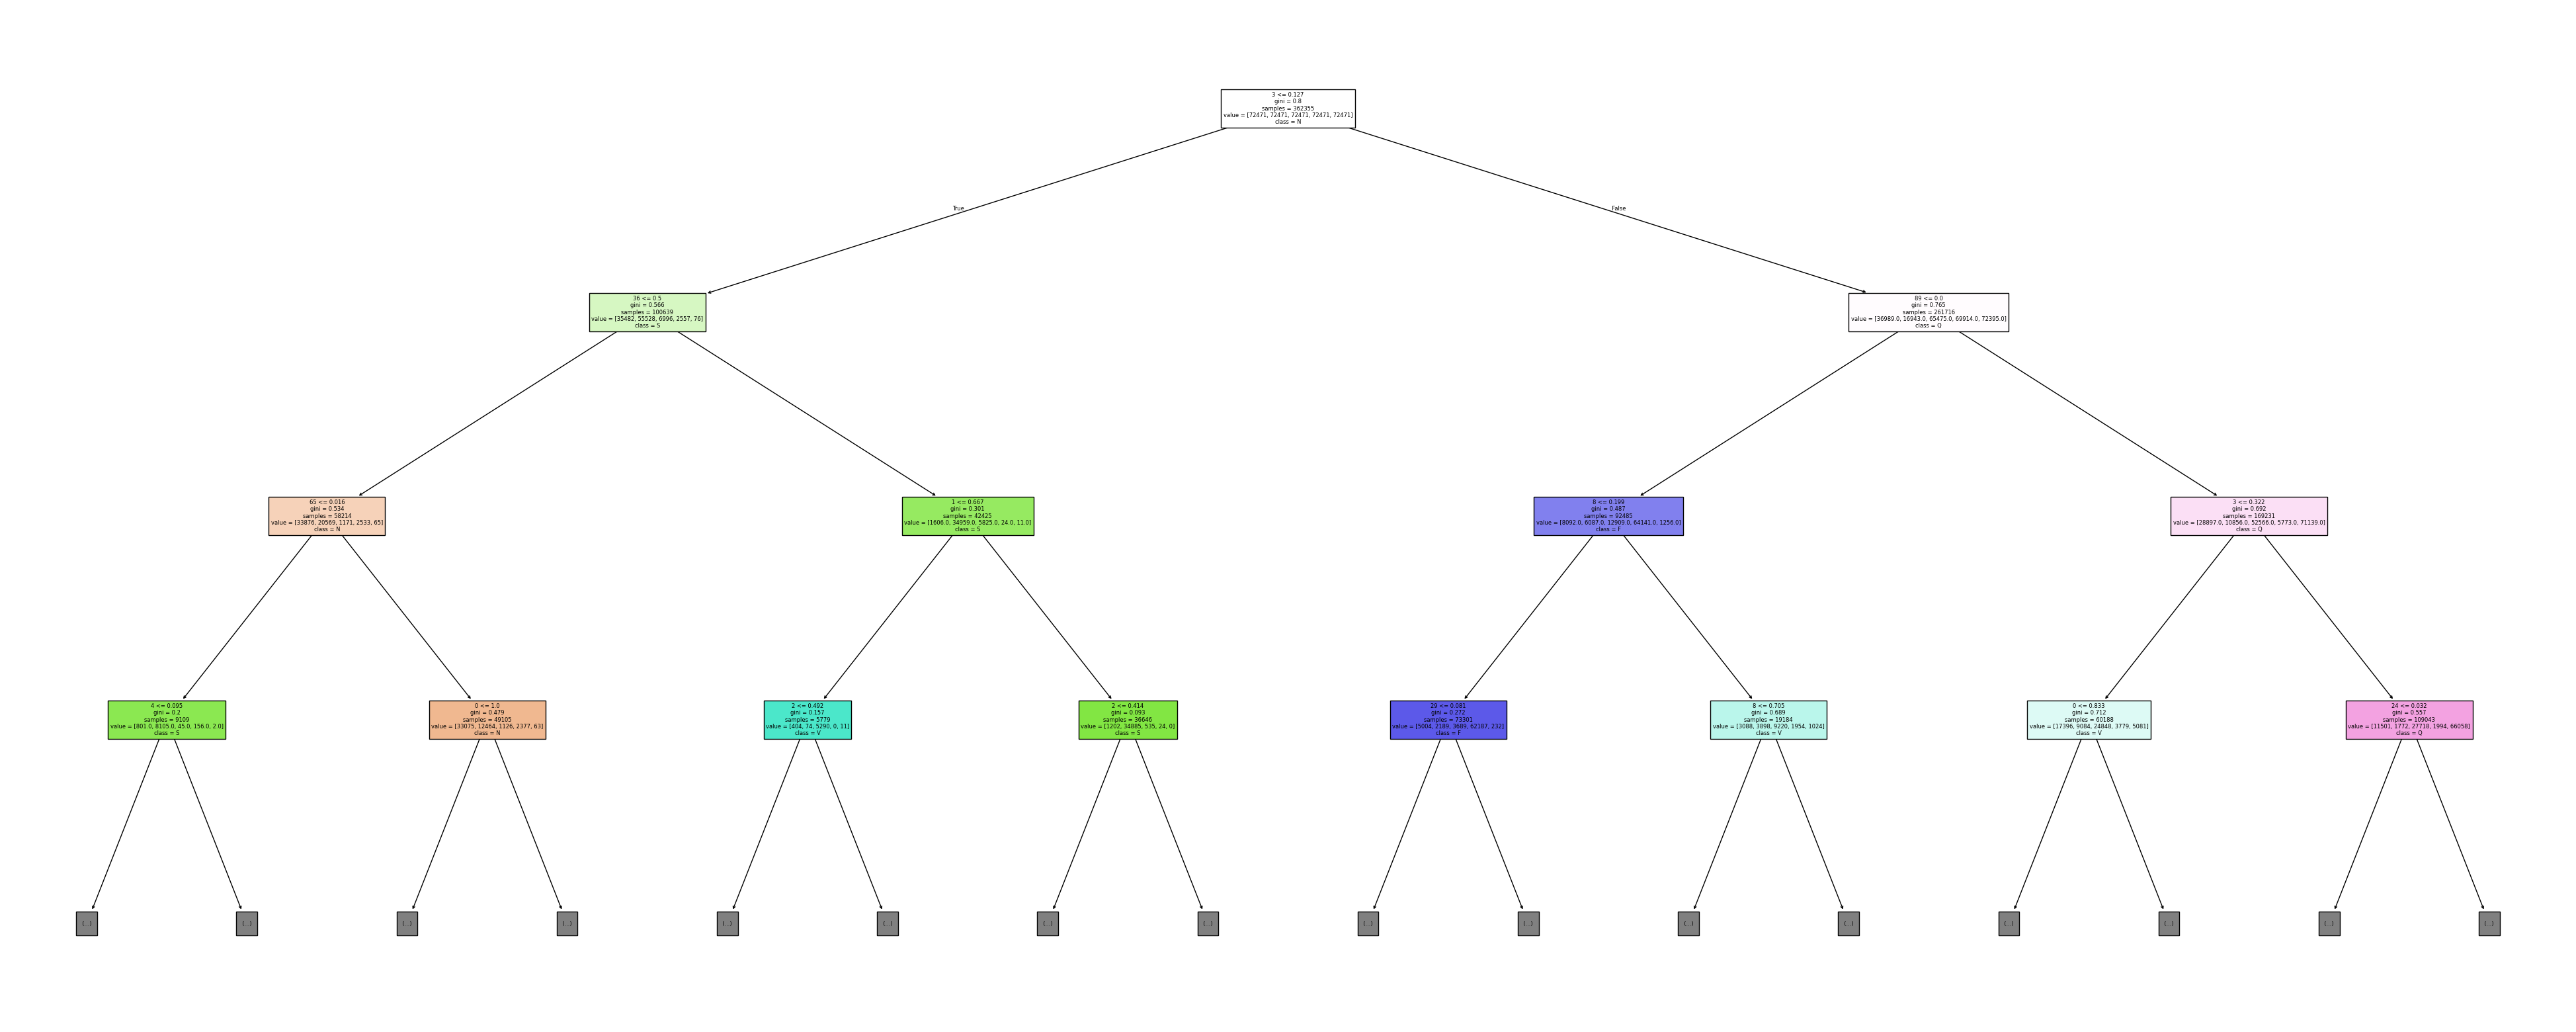

In [27]:
plt.figure(figsize=(50, 20))
plot_tree(dt, max_depth=3, feature_names=X_train.columns, class_names=['N','S','V','F','Q'], filled=True)
plt.show()

هني الموديل مو قاعد يفرق بين كلاسين اللي اهمه s,f مو قاعد يفرق بينهم ف بجرب موديل ثاني

## Try The Model Knn

In [28]:
scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train_resample)
X_test_scaler = scaler.transform(X_test)

In [29]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaler,y_train_resample)

KNeighborsClassifier()

In [30]:
knn.weights

'uniform'

In [31]:
y_pred_knn =knn.predict(X_test_scaler)
accuracy_score(y_test,y_pred_knn)*100

95.29051708386625

In [32]:
f1_score(y_test, y_pred_knn, average='weighted')*100

95.69743306852769

In [33]:
confusion_matrix(y_test, y_pred_knn)

array([[17347,   417,   187,   111,    56],
       [   81,   447,    22,     5,     1],
       [   26,    21,  1364,    30,     7],
       [   12,     2,    12,   136,     0],
       [   20,     6,    10,     5,  1567]])

In [34]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

         0.0       0.99      0.96      0.97     18118
         1.0       0.50      0.80      0.62       556
         2.0       0.86      0.94      0.90      1448
         3.0       0.47      0.84      0.61       162
         4.0       0.96      0.97      0.97      1608

    accuracy                           0.95     21892
   macro avg       0.76      0.90      0.81     21892
weighted avg       0.96      0.95      0.96     21892



صار افضل ويفرق بين n , s لان الموجات هني متشابهة شوي ف كانه نفس الشي يتم تصنيفهم و هاي احد لاسباب اللي ممكن الطبيب يخطا فيهم

## Try The Model NN

In [35]:
smote = SMOTE(random_state=42)
X_train_resample, y_train_resample = smote.fit_resample(X_train, y_train)

In [36]:
scaler_nn = StandardScaler()
X_train_scaler = scaler_nn.fit_transform(X_train_resample)
X_test_scaler = scaler_nn.transform(X_test)

In [37]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(187,)),
    Dense(64, activation='relu'),
    Dense(5, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        24,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,645 (127.52 KB)

 Trainable params: 32,645 (127.52 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [40]:
#checkpoint = tf.keras.callbacks.ModelCheckpoint("best_model.keras",save_best_only=True)


In [41]:
history = model.fit(X_train_scaler, y_train_resample, epochs=10, validation_split=0.2)

Epoch 1/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9340 - loss: 0.1860 - val_accuracy: 0.9564 - val_loss: 0.1377
Epoch 2/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 27s 3ms/step - accuracy: 0.9695 - loss: 0.0902 - val_accuracy: 0.9529 - val_loss: 0.1392
Epoch 3/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 25s 3ms/step - accuracy: 0.9772 - loss: 0.0698 - val_accuracy: 0.9809 - val_loss: 0.0684
Epoch 4/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 28s 3ms/step - accuracy: 0.9811 - loss: 0.0575 - val_accuracy: 0.9709 - val_loss: 0.0865
Epoch 5/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - accuracy: 0.9838 - loss: 0.0510 - val_accuracy: 0.9830 - val_loss: 0.0526
Epoch 6/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 31s 3ms/step - accuracy: 0.9858 - loss: 0.0446 - val_accuracy: 0.9839 - val_loss: 0.0528
Epoch 7/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9872 - loss: 0.0407 - val_accuracy: 0.9843 - val_loss: 0.0503
Epoch 8/10
9059/9059 ━━━━━━━━━━━━━━━━━━━━ 33s 4ms/step - accuracy: 0.9881 - loss: 0

In [42]:
history_df = pd.DataFrame(history.history)
history_df.head()

,accuracy,loss,val_accuracy,val_loss
0,0.934015,0.185980,0.956383,0.137733
1,0.969529,0.090178,0.952892,0.139245
2,0.977208,0.069785,0.980889,0.068396
3,0.981065,0.057521,0.970885,0.086510
4,0.983769,0.050981,0.982959,0.052622


<Axes: >

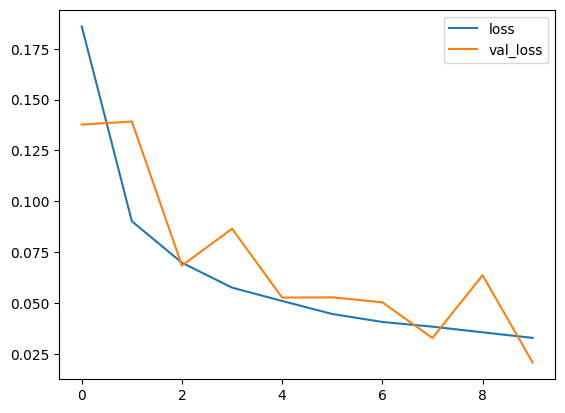

In [43]:
history_df[['loss','val_loss']].plot()


In [44]:
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)



685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [45]:
print(accuracy_score(y_test, y_pred))
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=['N', 'S', 'V', 'F', 'Q'],
    zero_division=0))
print(f1_score(y_test, y_pred, average='weighted'))

0.6703361958706376
              precision    recall  f1-score   support

           N       0.94      0.67      0.78     18118
           S       0.07      0.70      0.12       556
           V       0.49      0.54      0.51      1448
           F       0.00      0.00      0.00       162
           Q       0.89      0.88      0.88      1608

    accuracy                           0.67     21892
   macro avg       0.48      0.56      0.46     21892
weighted avg       0.87      0.67      0.75     21892

0.7466657465926227


## Try The Model CNN

In [46]:
model = Sequential([
    Conv1D(32, 3, activation='relu', input_shape=(187, 1)),
    MaxPooling1D(2),

    Conv1D(64, 3, activation='relu'),
    MaxPooling1D(2),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(5, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [47]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 185, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 92, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 90, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 45, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2880)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       184,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 191,045 (746.27 KB)

 Trainable params: 191,045 (746.27 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
history = model.fit(X_train,y_train,epochs=10,validation_data=(X_test, y_test))

Epoch 1/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 43s 15ms/step - accuracy: 0.9423 - loss: 0.2105 - val_accuracy: 0.9580 - val_loss: 0.1502
Epoch 2/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 42s 15ms/step - accuracy: 0.9672 - loss: 0.1170 - val_accuracy: 0.9693 - val_loss: 0.1173
Epoch 3/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 43s 16ms/step - accuracy: 0.9739 - loss: 0.0921 - val_accuracy: 0.9715 - val_loss: 0.1058
Epoch 4/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 44s 16ms/step - accuracy: 0.9775 - loss: 0.0783 - val_accuracy: 0.9761 - val_loss: 0.0891
Epoch 5/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 48s 18ms/step - accuracy: 0.9805 - loss: 0.0678 - val_accuracy: 0.9783 - val_loss: 0.0877
Epoch 6/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 49s 18ms/step - accuracy: 0.9823 - loss: 0.0598 - val_accuracy: 0.9747 - val_loss: 0.0964
Epoch 7/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 44s 16ms/step - accuracy: 0.9842 - loss: 0.0535 - val_accuracy: 0.9778 - val_loss: 0.0862
Epoch 8/10
2737/2737 ━━━━━━━━━━━━━━━━━━━━ 43s 16ms/step - accuracy: 0.9854 -

In [49]:
history_df = pd.DataFrame(history.history)
history_df.head()

,accuracy,loss,val_accuracy,val_loss
0,0.942344,0.210489,0.958021,0.150175
1,0.967197,0.116971,0.969258,0.117258
2,0.973879,0.092130,0.971496,0.105816
3,0.977545,0.078342,0.976064,0.089131
4,0.980503,0.067844,0.978303,0.087709


<Axes: >

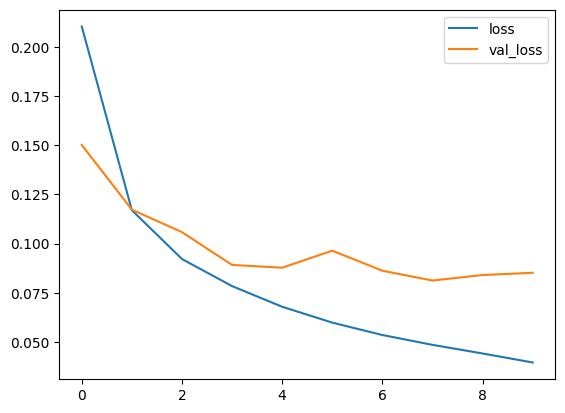

In [50]:
history_df[['loss','val_loss']].plot()

In [51]:
y_pred = model.predict(X_test)
y_pred = np.argmax(y_pred, axis=1)

print(accuracy_score(y_test, y_pred))

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=['N', 'S', 'V', 'F', 'Q'],
    zero_division=0
))
print(f1_score(y_test, y_pred, average='weighted'))

685/685 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
0.9815914489311164
              precision    recall  f1-score   support

           N       0.99      1.00      0.99     18118
           S       0.93      0.71      0.81       556
           V       0.95      0.94      0.95      1448
           F       0.85      0.70      0.77       162
           Q       0.99      0.98      0.99      1608

    accuracy                           0.98     21892
   macro avg       0.94      0.87      0.90     21892
weighted avg       0.98      0.98      0.98     21892

0.9808902371168174


## choose the best model
- to check in the streamlit than connect it with circuit and watch
-- try data from apple watch